# SWAP AND TWO-QUBIT GATE COUNTS

## Imports

In [1]:
from helper_functions import (
    return_ops_all_methods,
    plot_swap_results,
    compute_all_improvements,
    plot_percentage_improvements
)

from qiskit_ibm_runtime.fake_provider import FakeMarrakesh

import warnings
warnings.filterwarnings("ignore")

## FakeMarrakesh

In [2]:
backend = FakeMarrakesh()

### SWAP COUNTS

Random Regular Graphs

In [3]:
nodes_reg = list(range(10, 101, 2))
params_reg = list(range(3, 9, 1))
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops_all_methods(backend, 
                                              graph_type='reg', 
                                              param=param,
                                              average_over=10, 
                                              node_list=nodes_reg, 
                                              k_list=[2,3,4], 
                                              op_name='swap',
                                              reps=1, 
                                              noise_aware=True, 
                                              stop_after_routing=True)

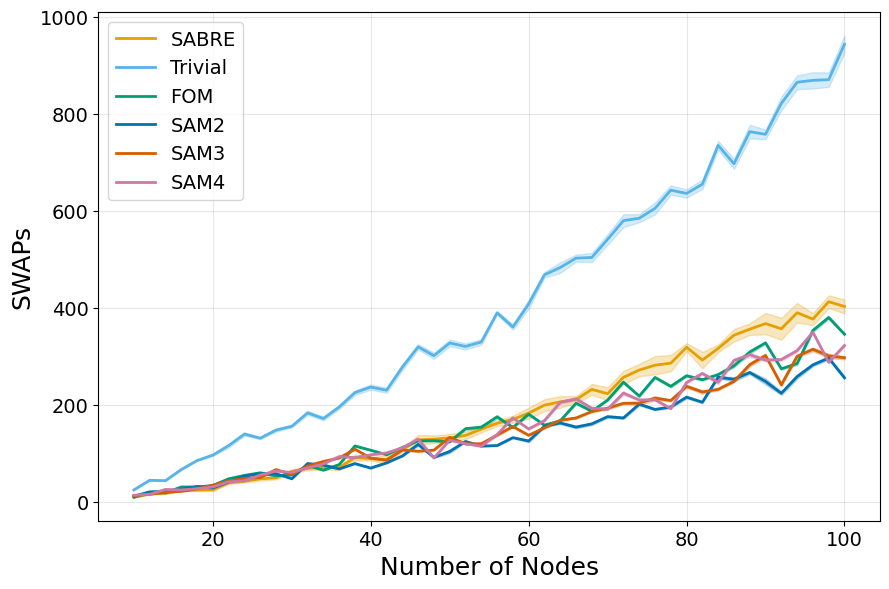

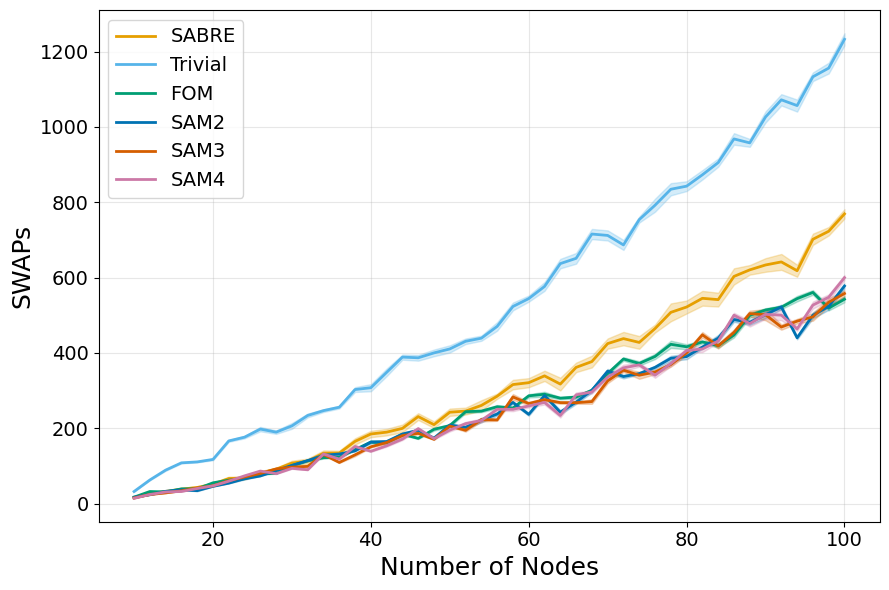

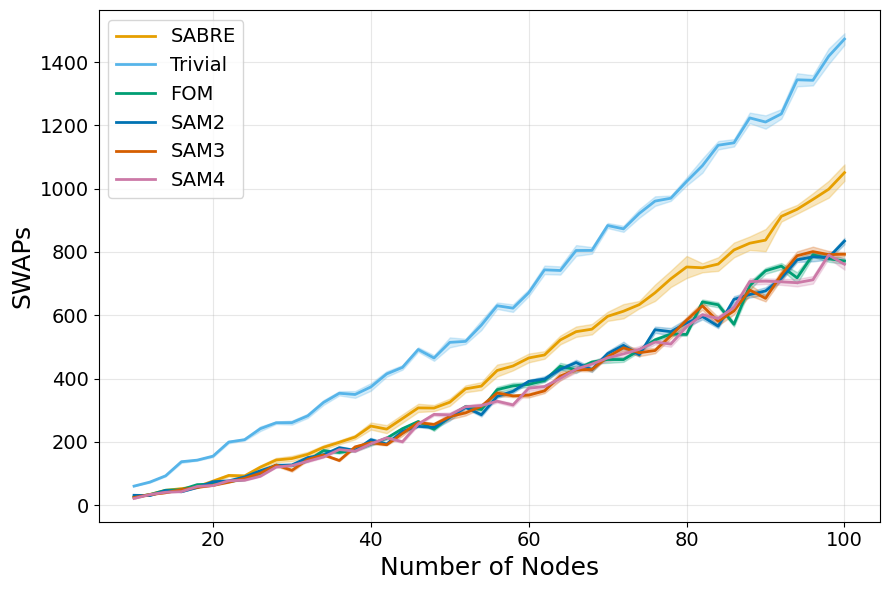

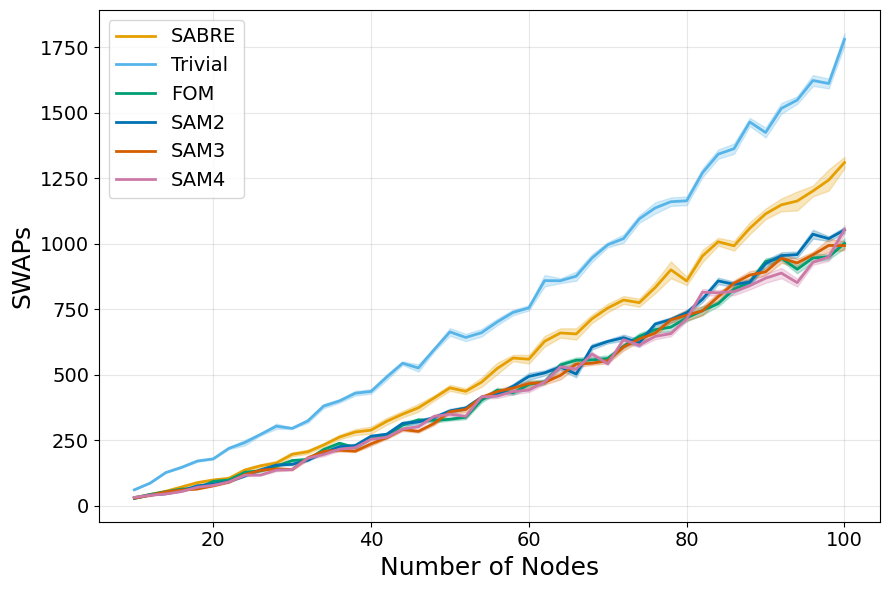

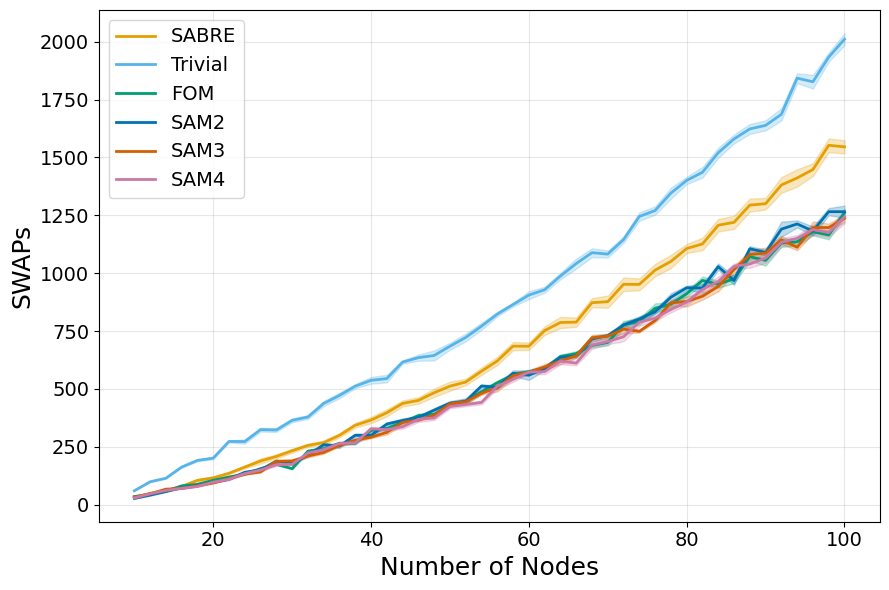

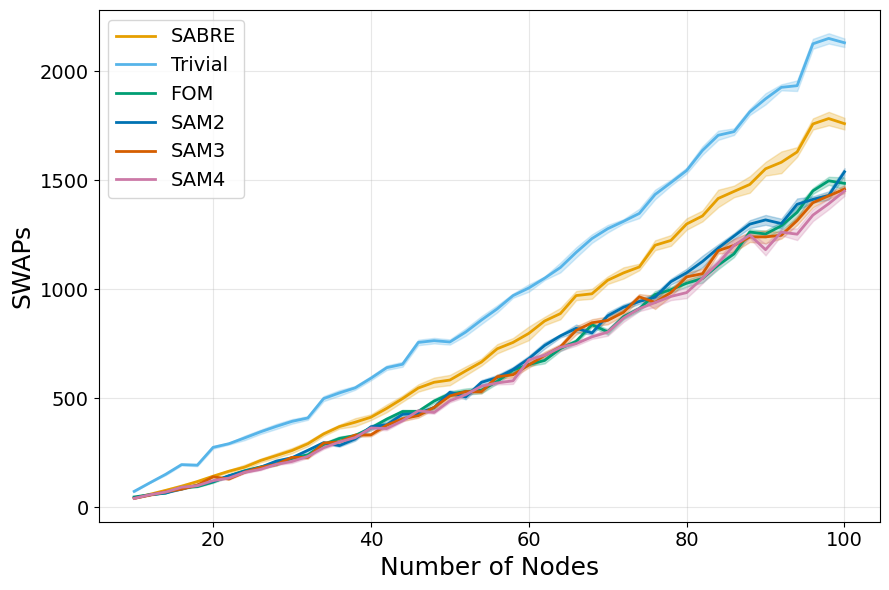

In [4]:
plot_swap_results(swaps_reg, node_list=nodes_reg, k_list=[2,3,4], params=params_reg, ylabel="SWAPs")

BA Graphs

In [5]:
nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops_all_methods(backend, 
                                             graph_type='ba', 
                                             param=param,
                                             average_over=10, 
                                             node_list=nodes_ba, 
                                             k_list=[2,3,4], 
                                             op_name='swap', 
                                             reps=1, 
                                             noise_aware=True, 
                                             stop_after_routing=True)

Iterating for number of nodes (param=2):   0%|          | 0/48 [00:00<?, ?it/s]

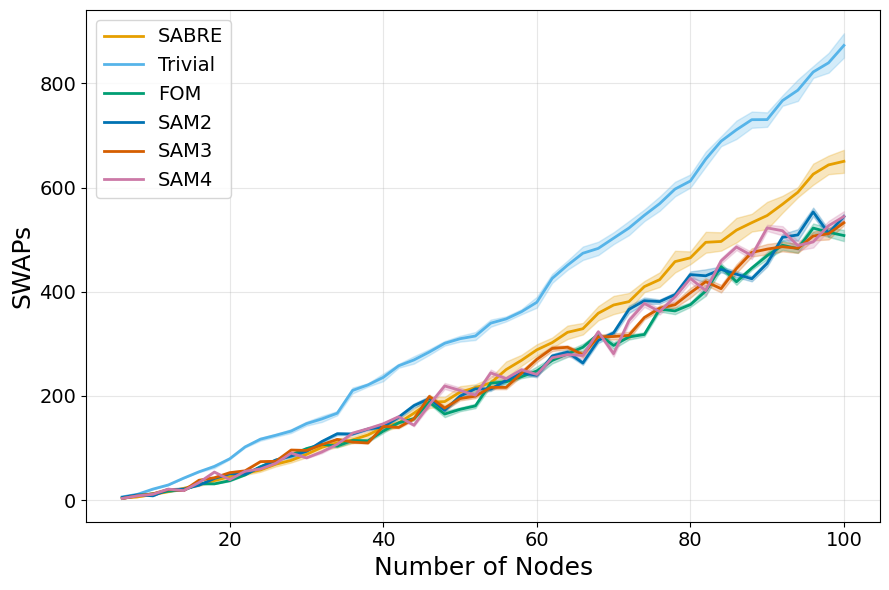

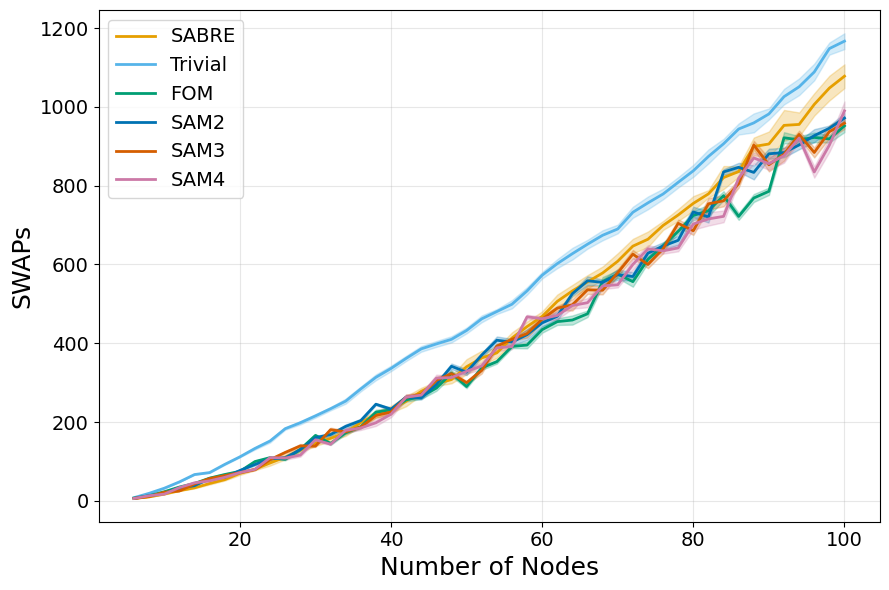

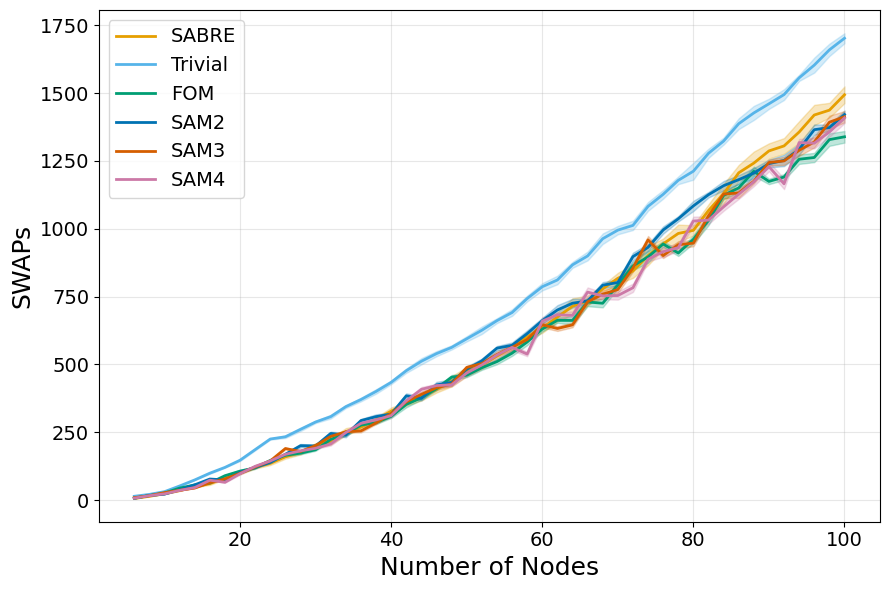

In [6]:
plot_swap_results(swaps_ba, node_list=nodes_ba, k_list=[2,3,4], params=params_ba, ylabel="SWAPs")

### TWO-QUBIT GATES

Random Regular Graphs

In [7]:
nodes_reg = list(range(10, 101, 2))
params_reg = list(range(3,9,1))
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']
twoq_reg={}
for param in params_reg:
    twoq_reg[param] = return_ops_all_methods(backend, 
                                             graph_type='reg', 
                                             param=param,
                                             average_over=10, 
                                             node_list=nodes_reg, 
                                             k_list=[2,3,4],
                                             op_name='cz',
                                             opt_level=1, 
                                             reps=1, 
                                             noise_aware=True)

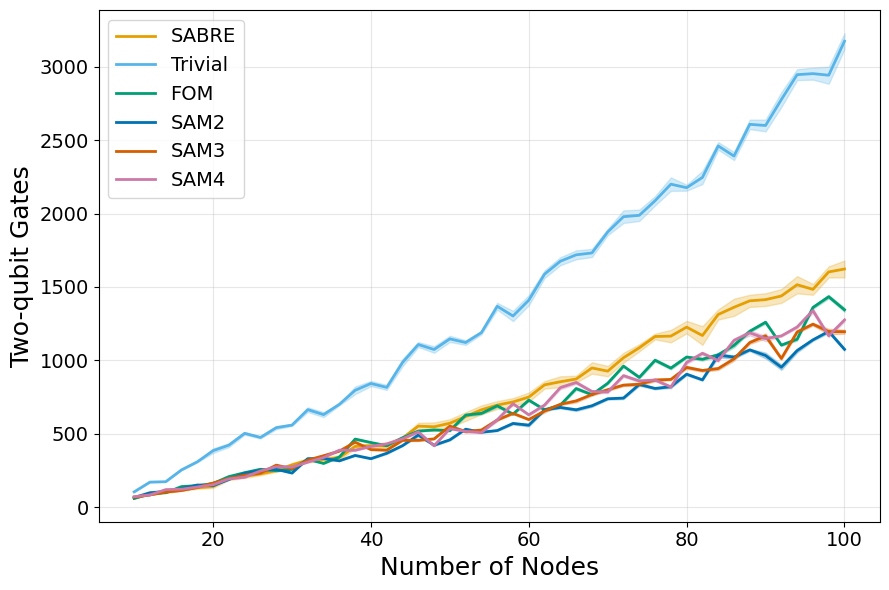

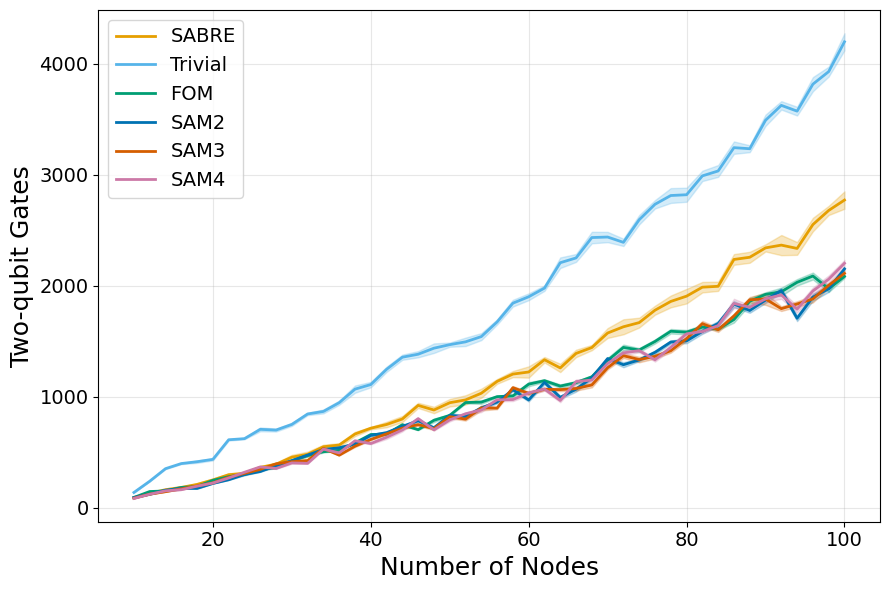

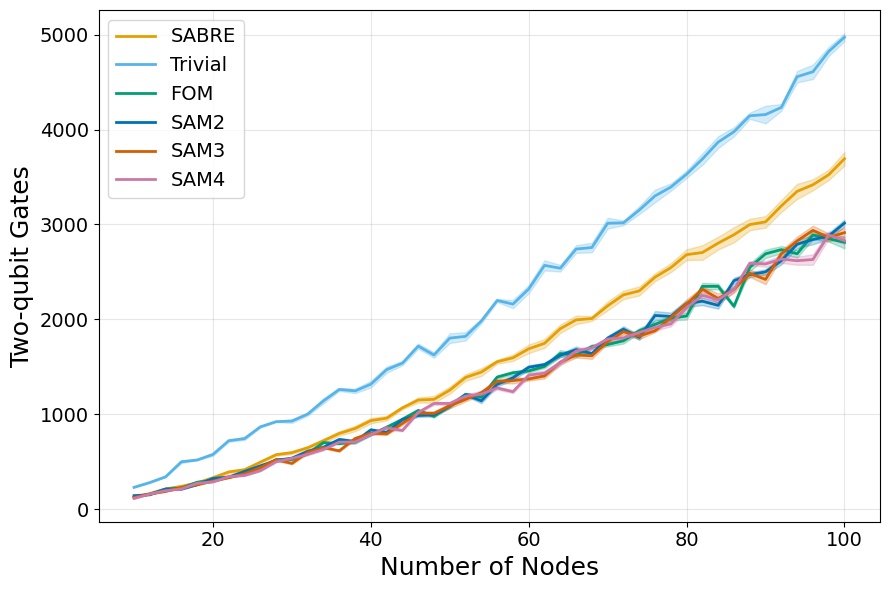

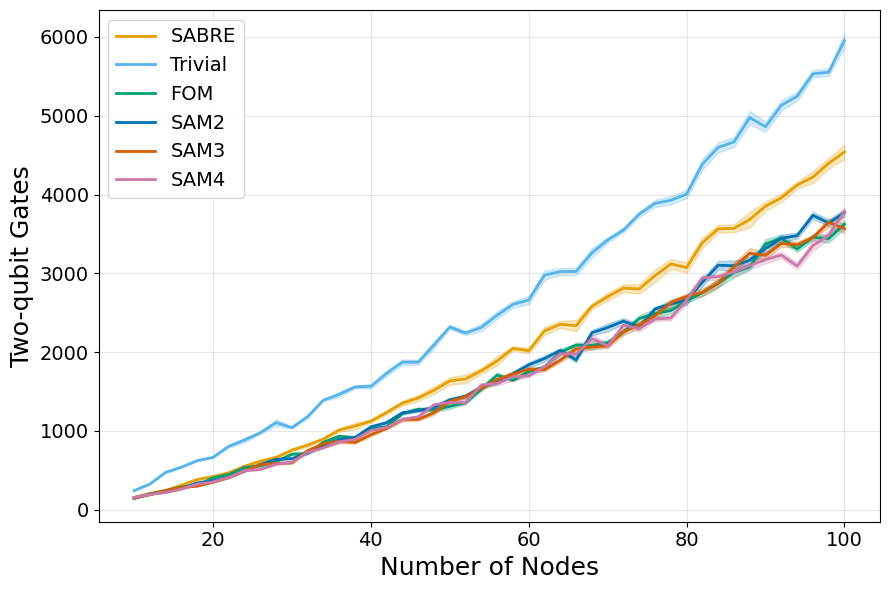

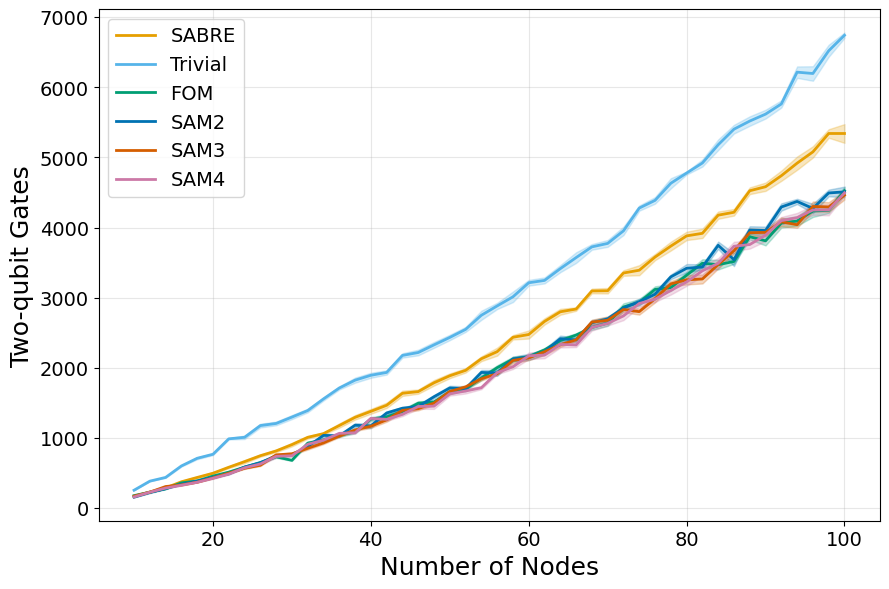

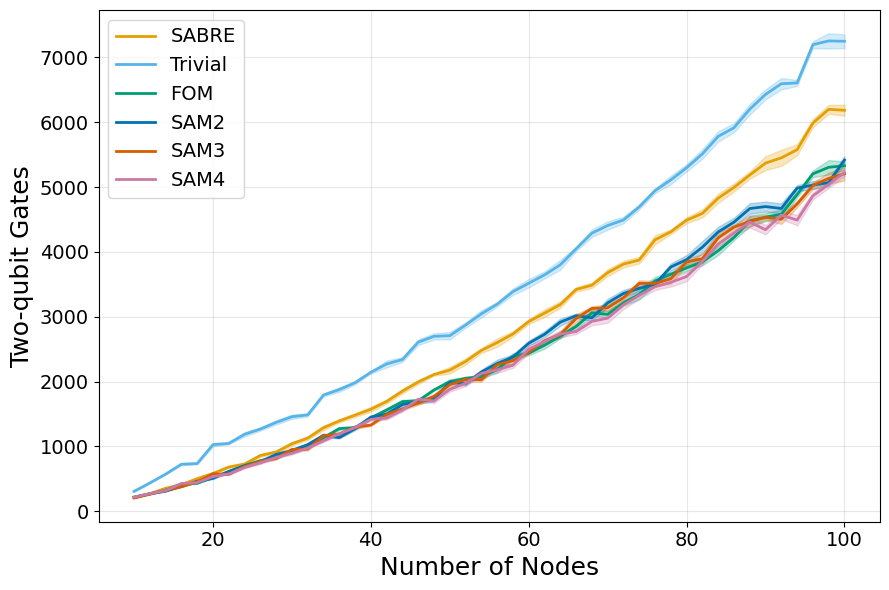

In [8]:
plot_swap_results(twoq_reg, node_list=nodes_reg, k_list=[2,3,4], params=params_reg, ylabel="Two-qubit Gates")

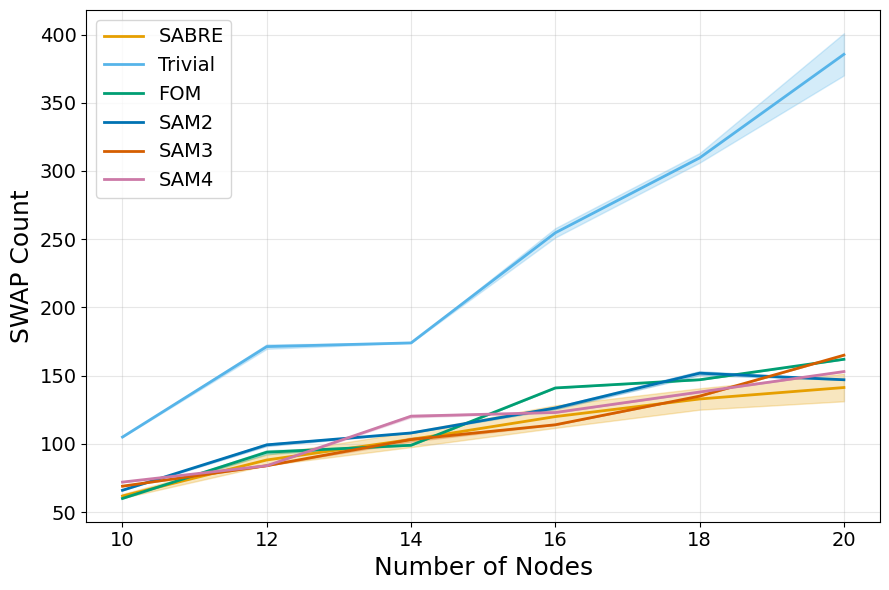

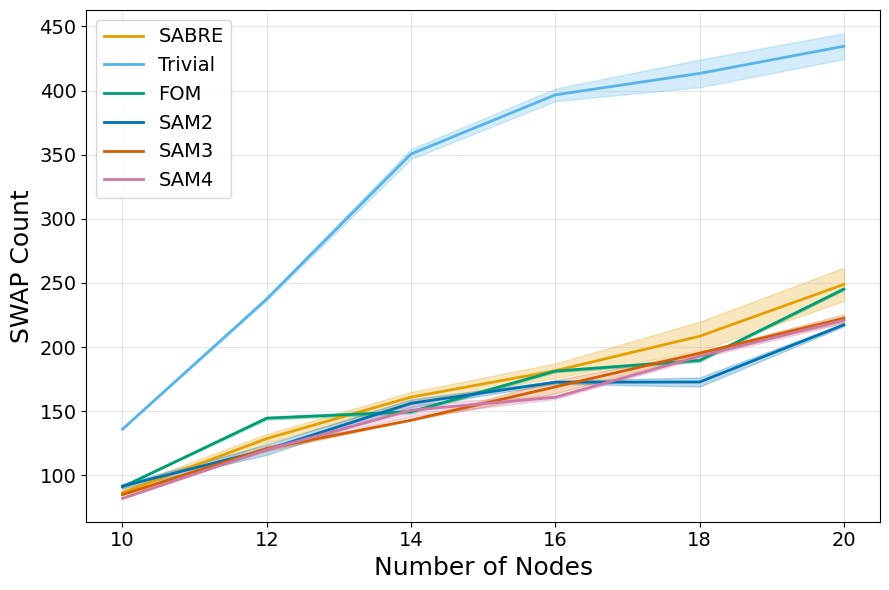

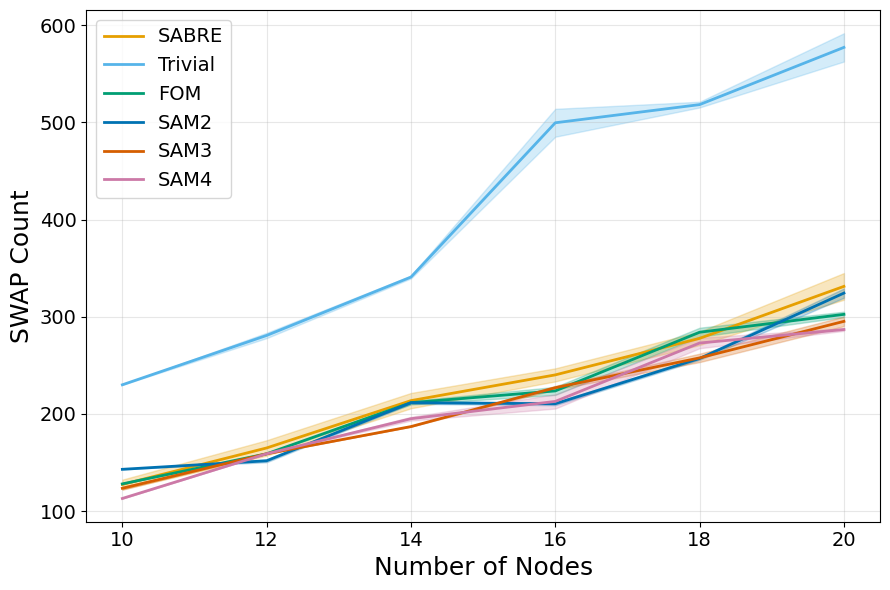

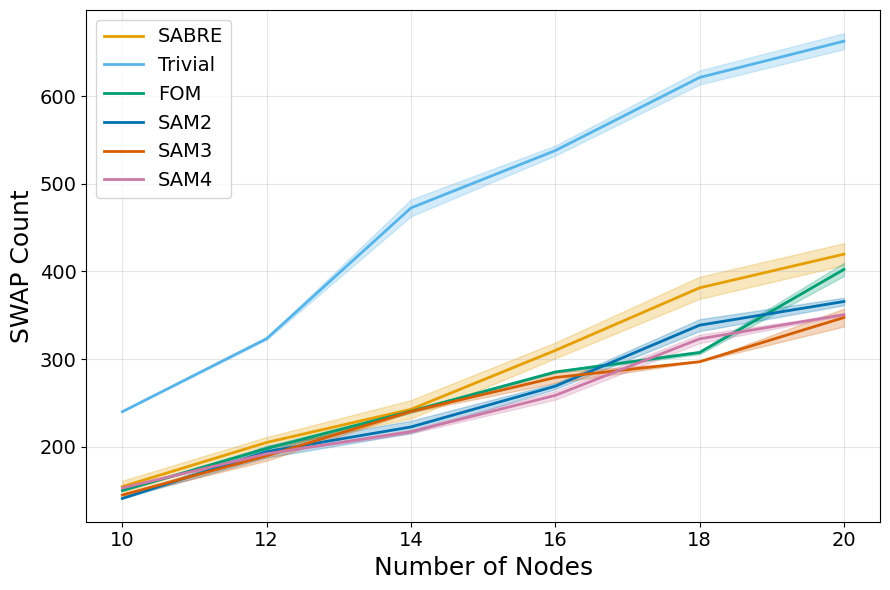

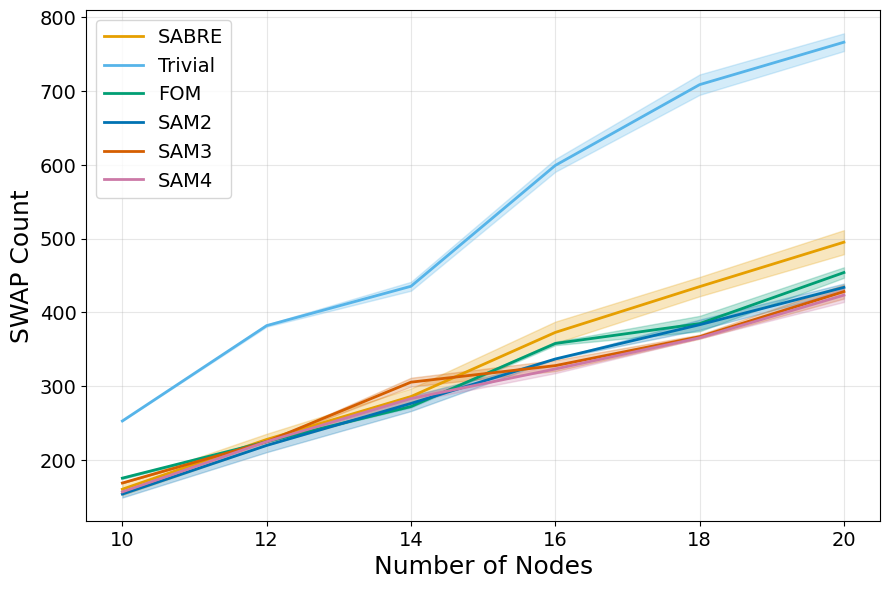

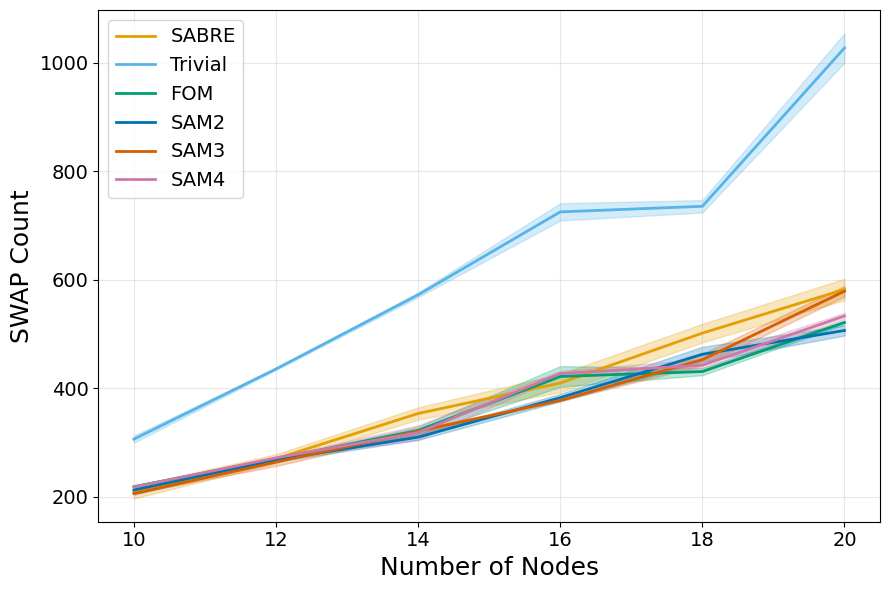

In [9]:
plot_swap_results(twoq_reg, node_list=nodes_reg, k_list=[2,3,4], params=params_reg, zoom=6)

BA Graphs

In [10]:
nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial'] 
twoq_ba={}
for param in params_ba:
    twoq_ba[param] = return_ops_all_methods(backend, 
                                            graph_type='ba', 
                                            param=param,
                                            average_over=10, 
                                            node_list=nodes_ba, 
                                            k_list=[2,3,4],
                                            op_name='cz', 
                                            opt_level=1, 
                                            reps=1, 
                                            noise_aware=True, 
                                            stop_after_routing=False)

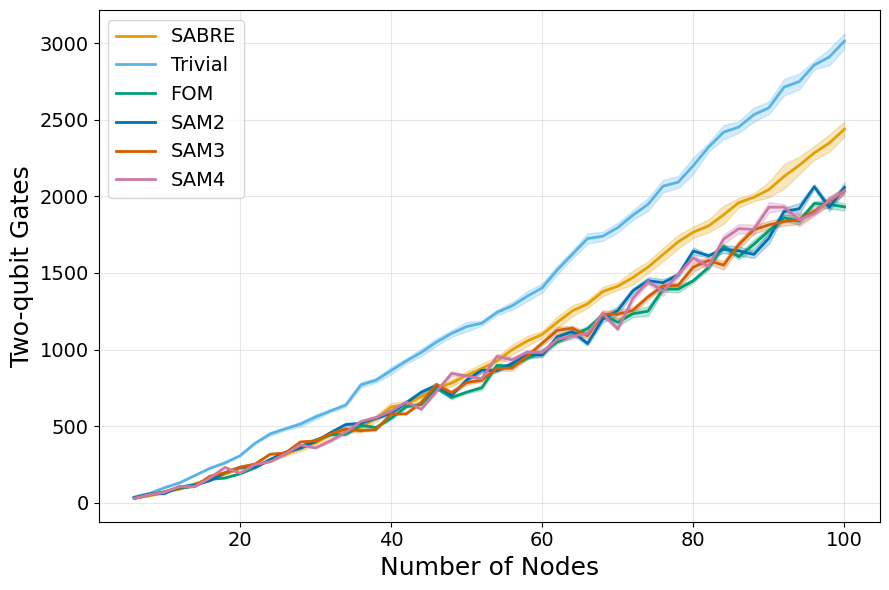

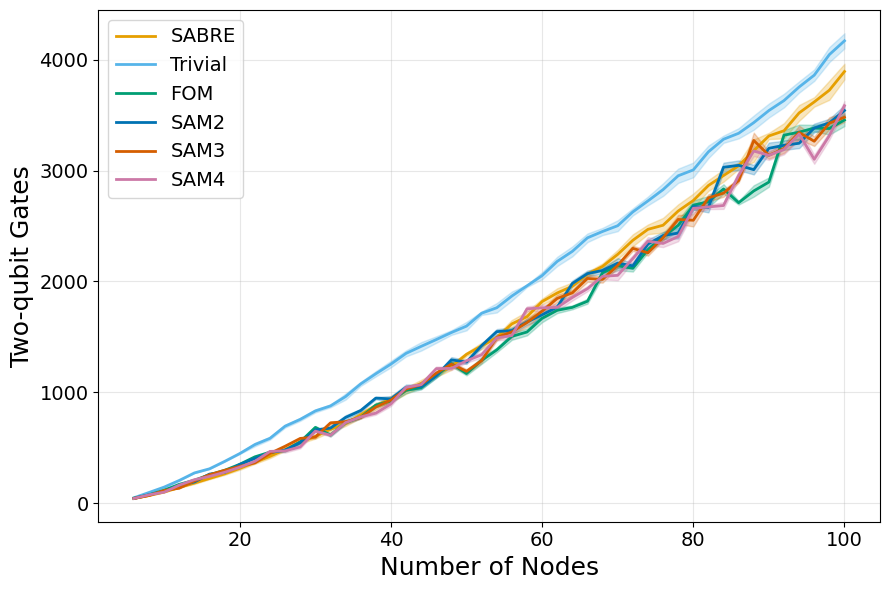

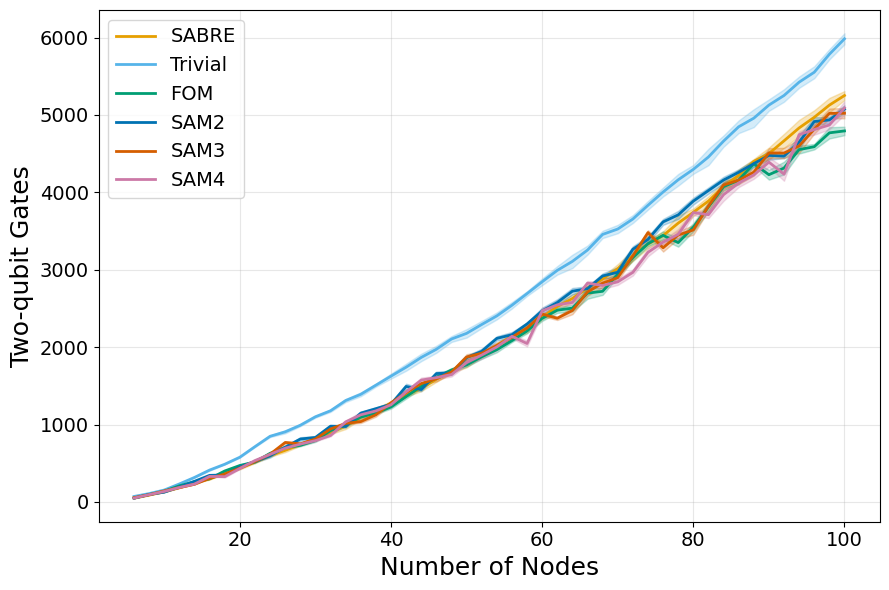

In [11]:
plot_swap_results(twoq_ba, node_list=nodes_ba, k_list=[2,3,4], params=params_ba, ylabel="Two-qubit Gates")

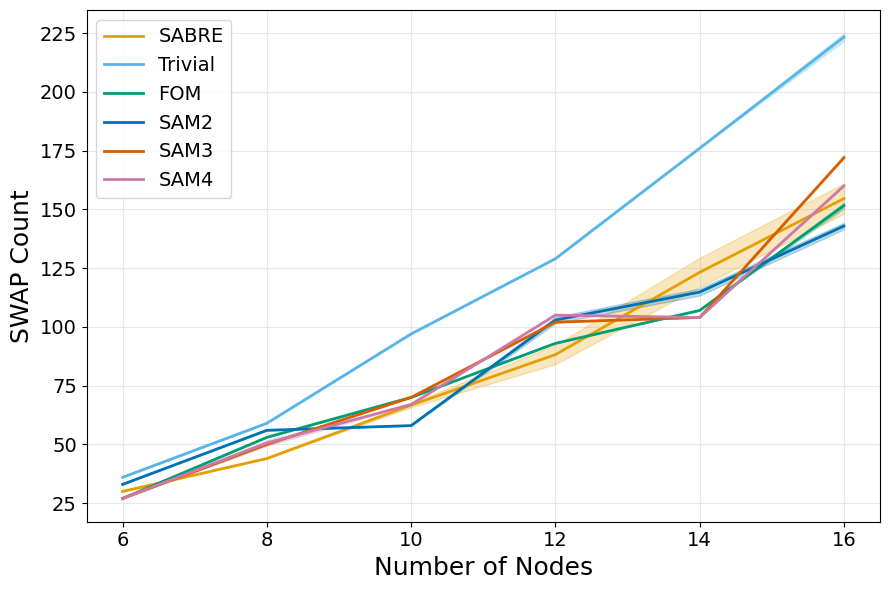

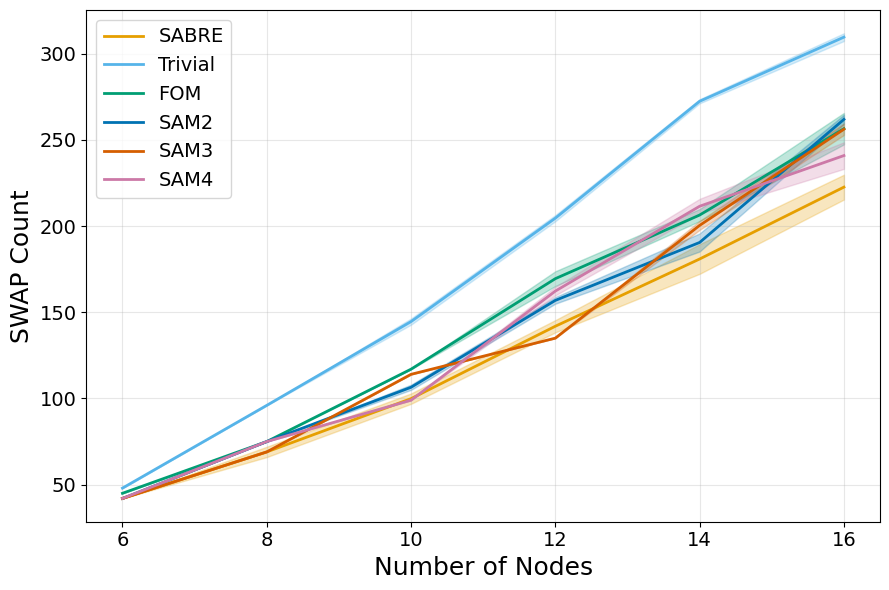

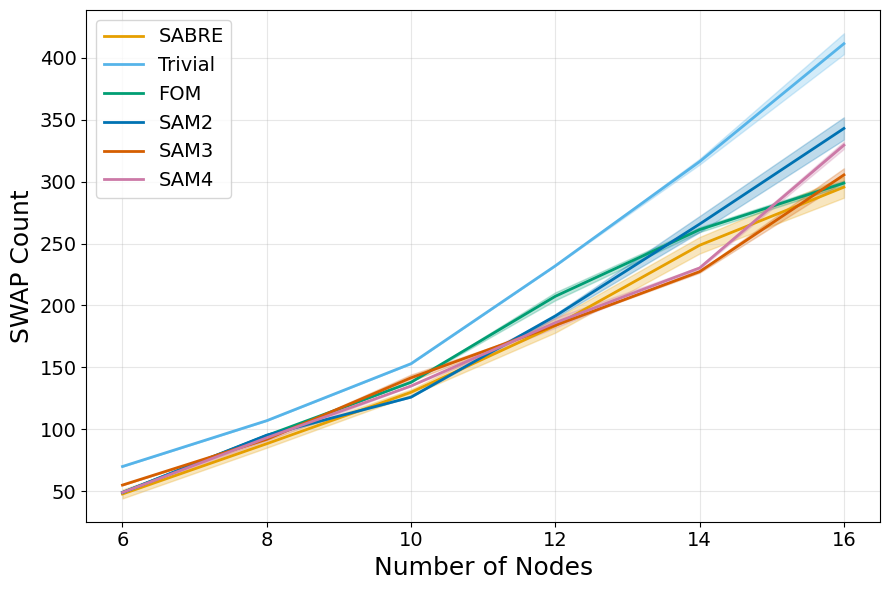

In [12]:
plot_swap_results(twoq_ba, node_list=nodes_ba, k_list=[2,3,4], params=params_ba, zoom=6)

### Percentage Improvements over SabreLayout

In [13]:
swap_imp_reg = compute_all_improvements(swaps_reg, k_list=[2,3,4], baseline="SABRE")
swap_imp_ba = compute_all_improvements(swaps_ba, k_list=[2,3,4], baseline="SABRE")

twoq_imp_reg = compute_all_improvements(twoq_reg, k_list=[2,3,4], baseline="SABRE")
twoq_imp_ba = compute_all_improvements(twoq_ba, k_list=[2,3,4], baseline="SABRE")

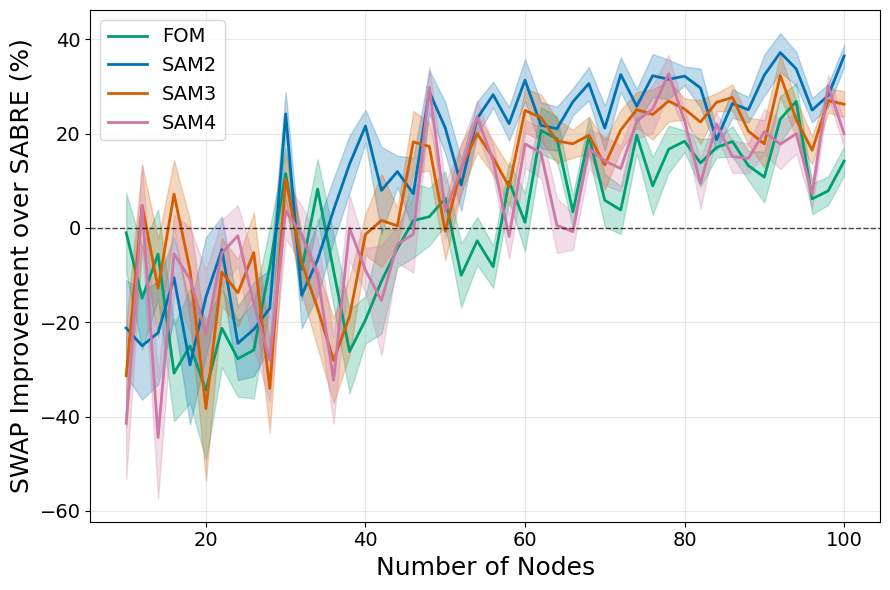

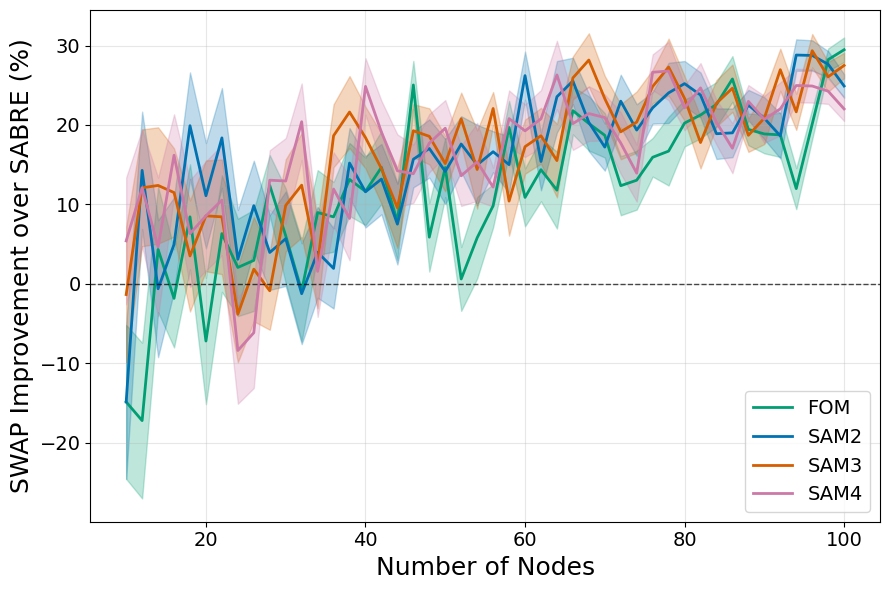

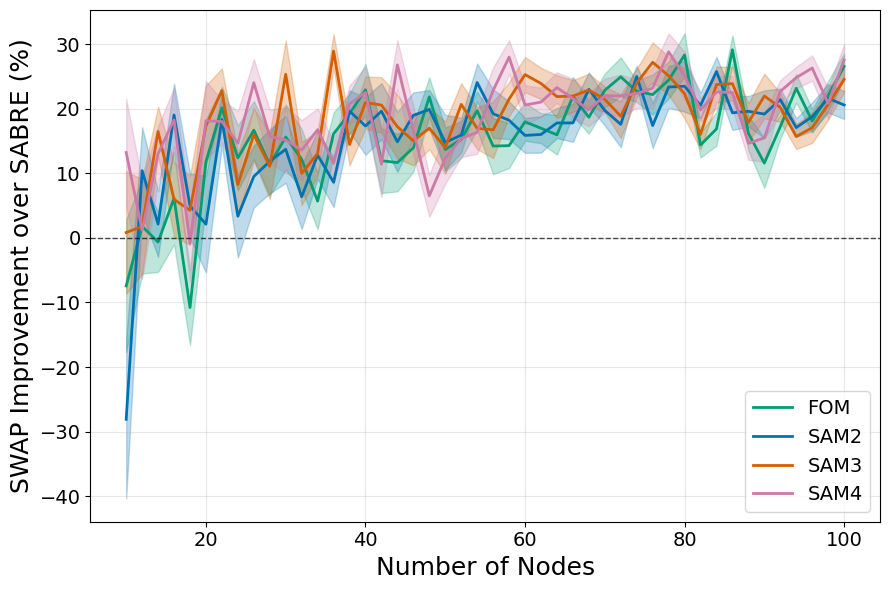

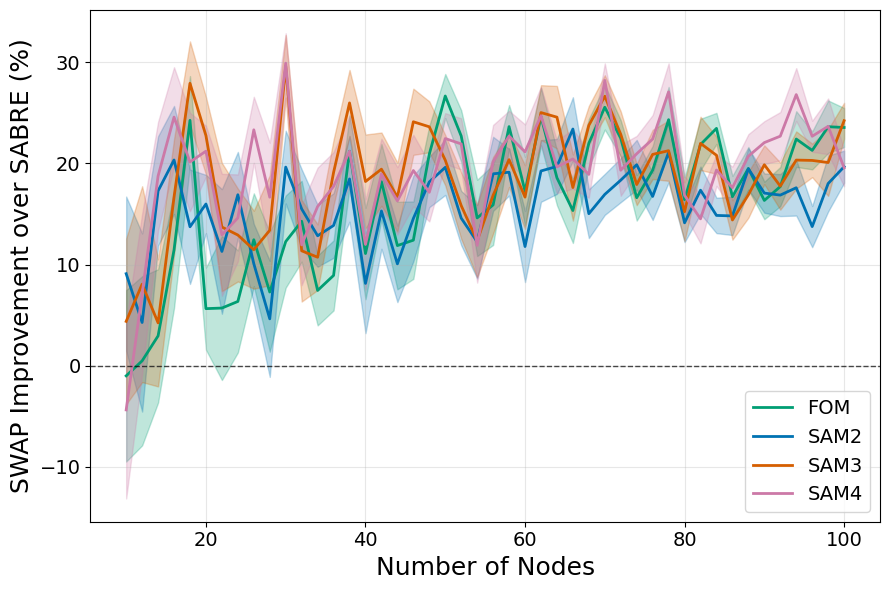

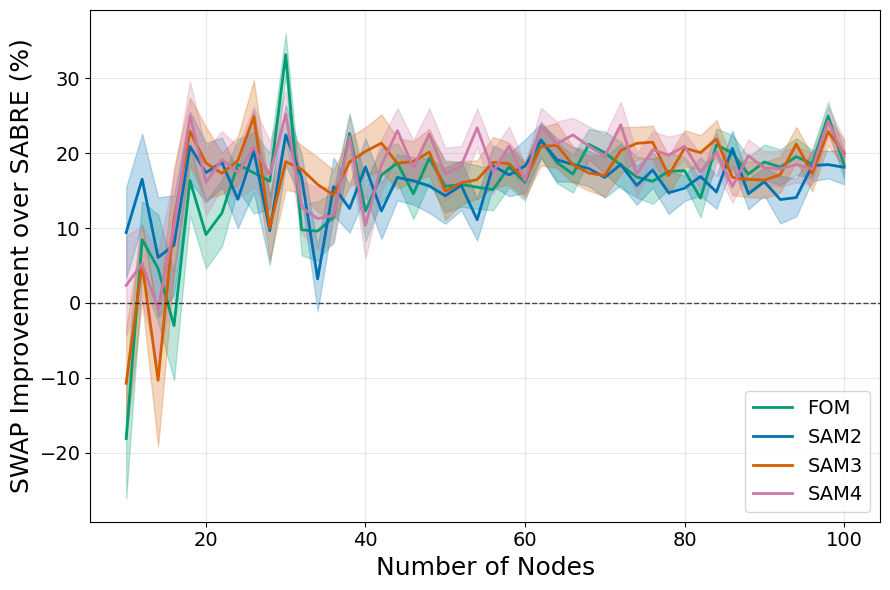

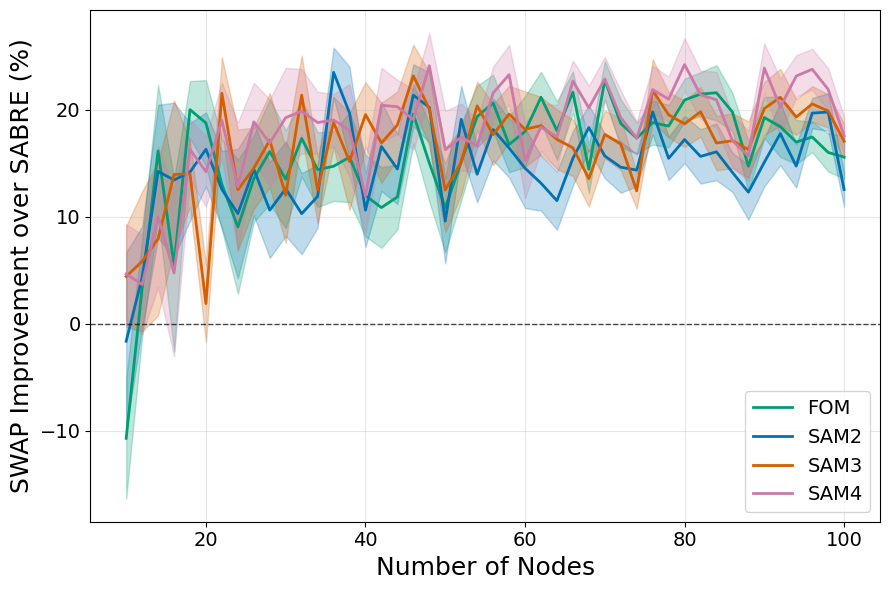

In [14]:
plot_percentage_improvements(swap_imp_reg, node_list=nodes_reg, k_list=[2,3,4], params=params_reg, ylabel="SWAP Improvement over SABRE (%)")


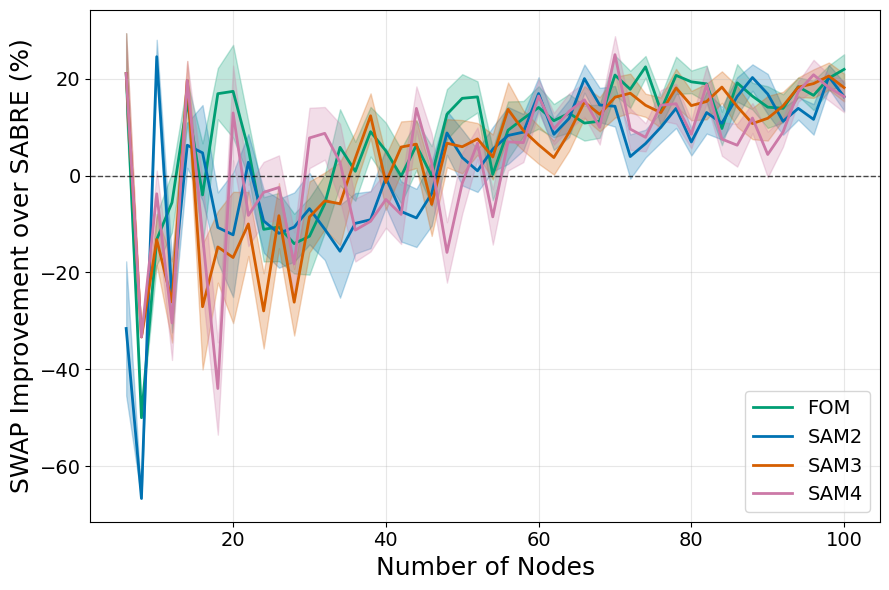

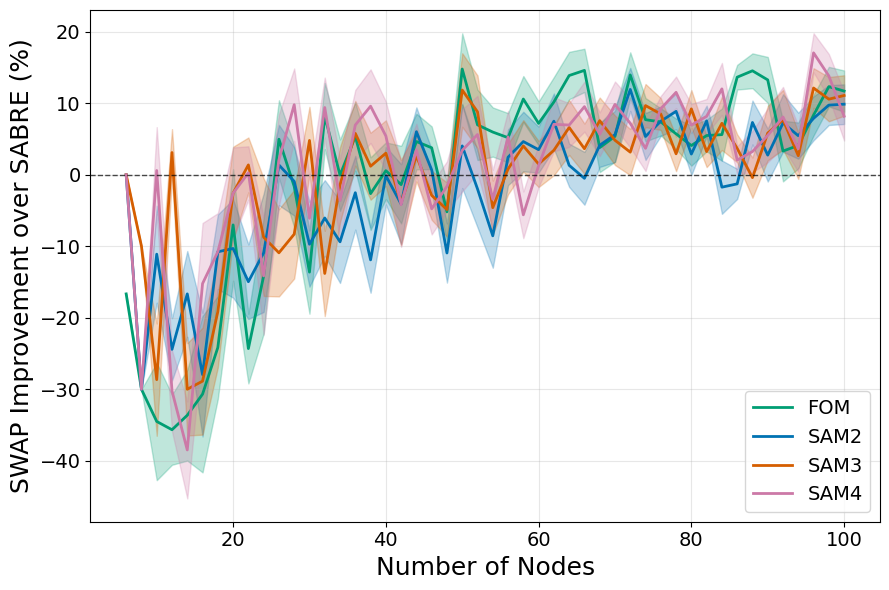

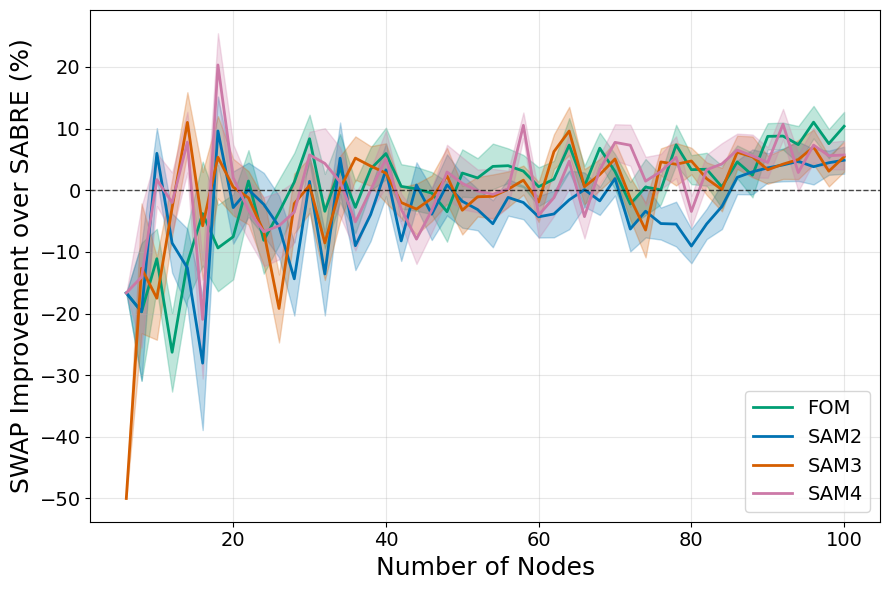

In [15]:
plot_percentage_improvements(swap_imp_ba, node_list=nodes_ba, k_list=[2,3,4], params=params_ba, ylabel="SWAP Improvement over SABRE (%)")


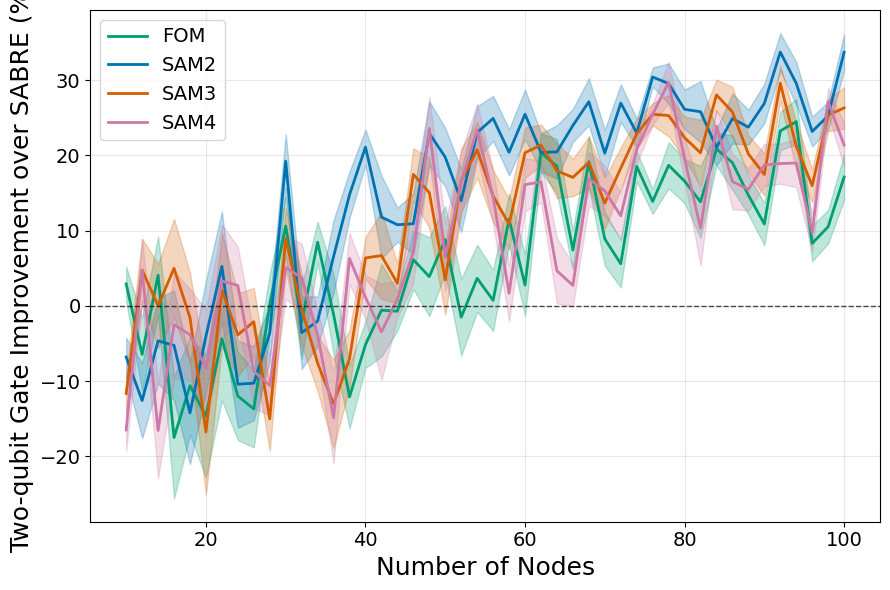

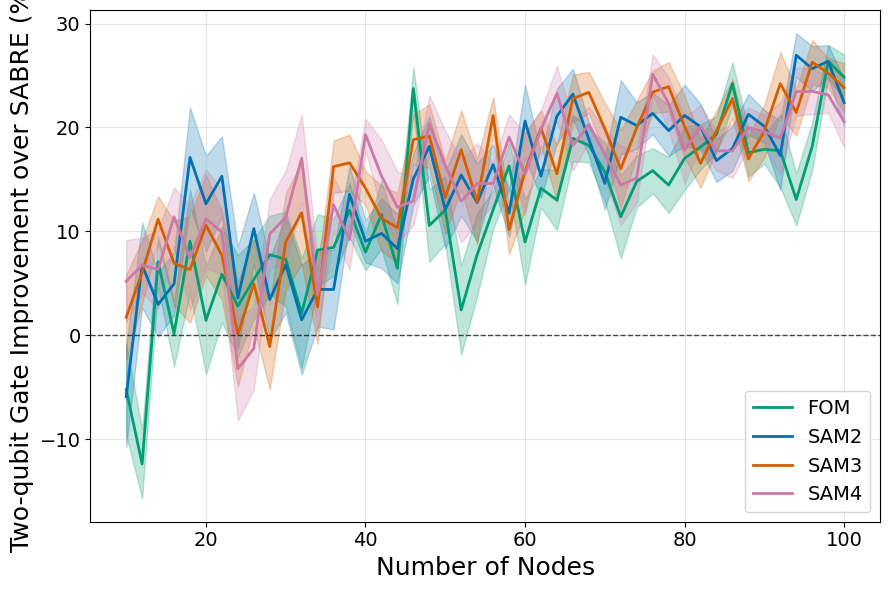

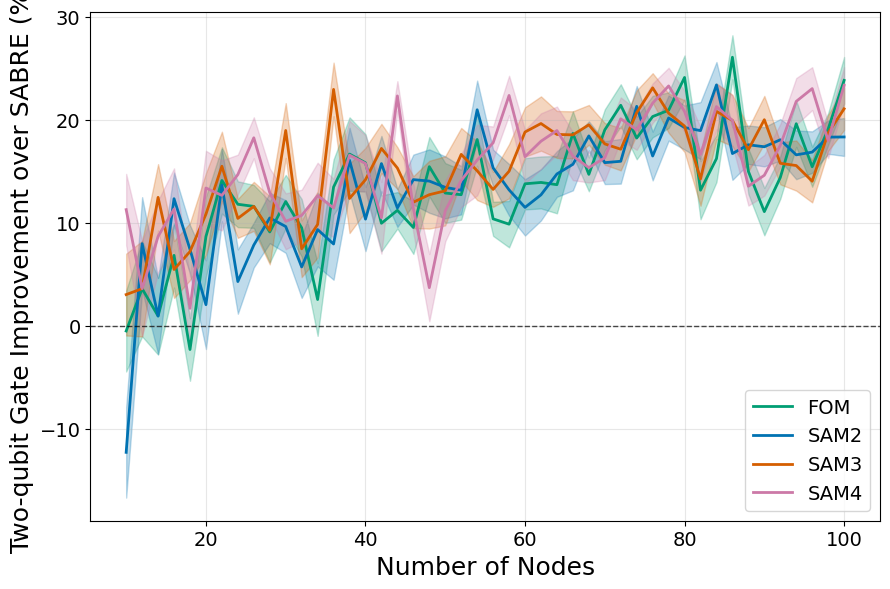

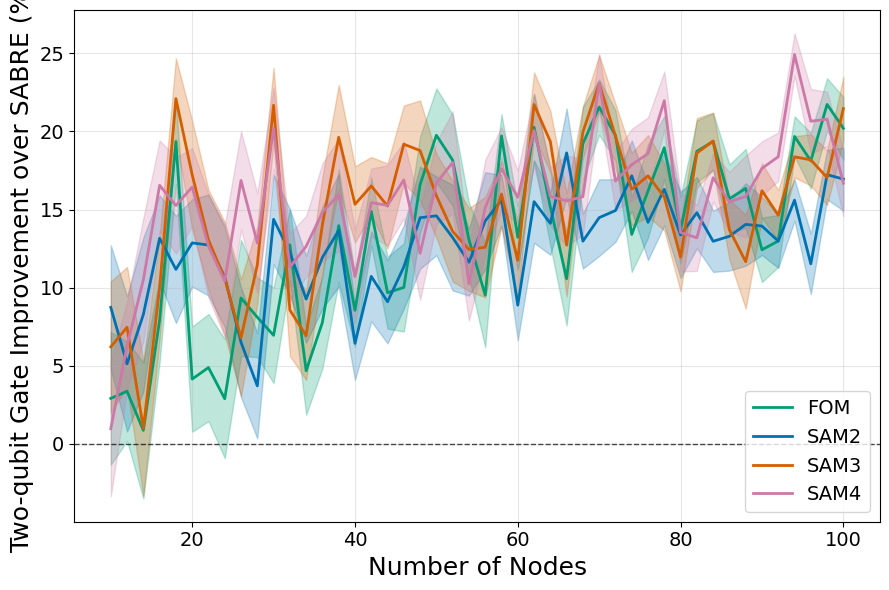

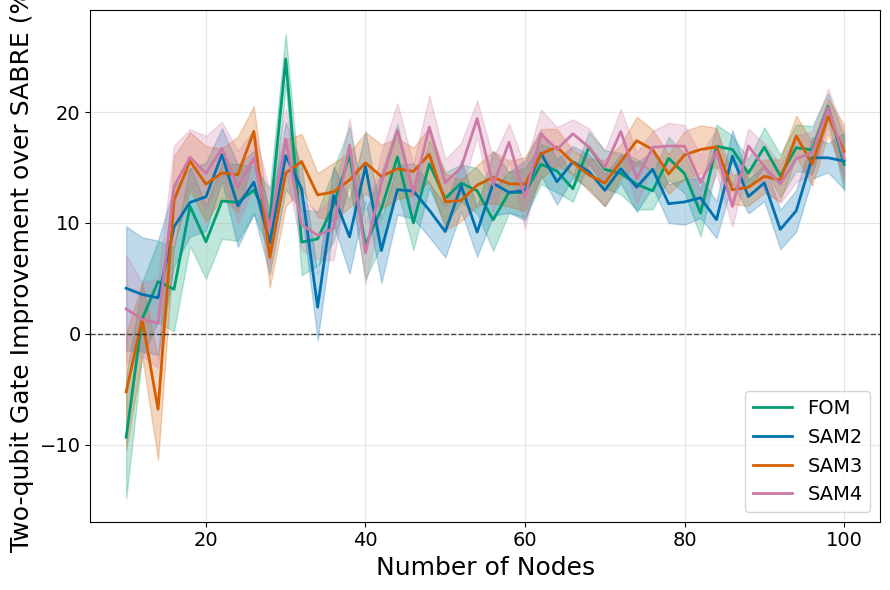

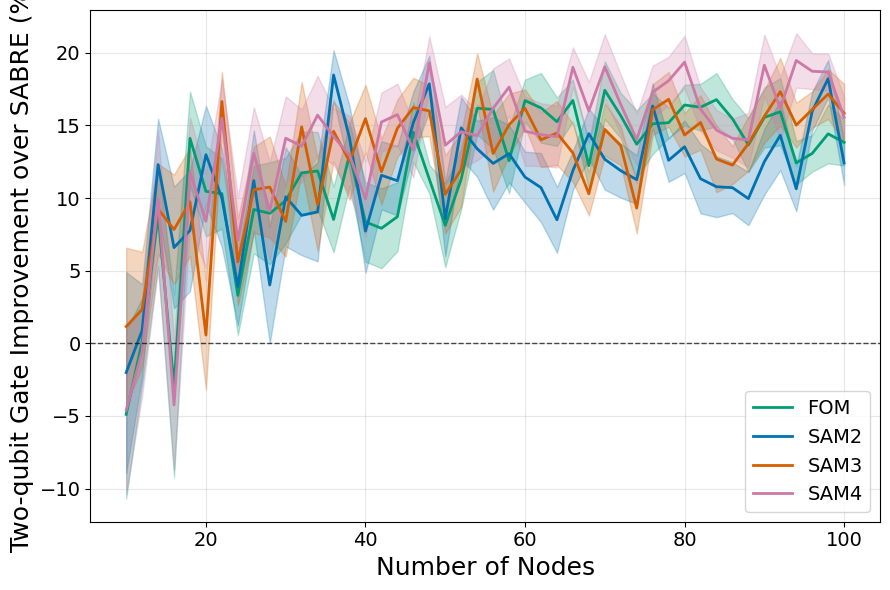

In [16]:
plot_percentage_improvements(twoq_imp_reg, node_list=nodes_reg, k_list=[2,3,4], params=params_reg, ylabel="Two-qubit Gate Improvement over SABRE (%)")


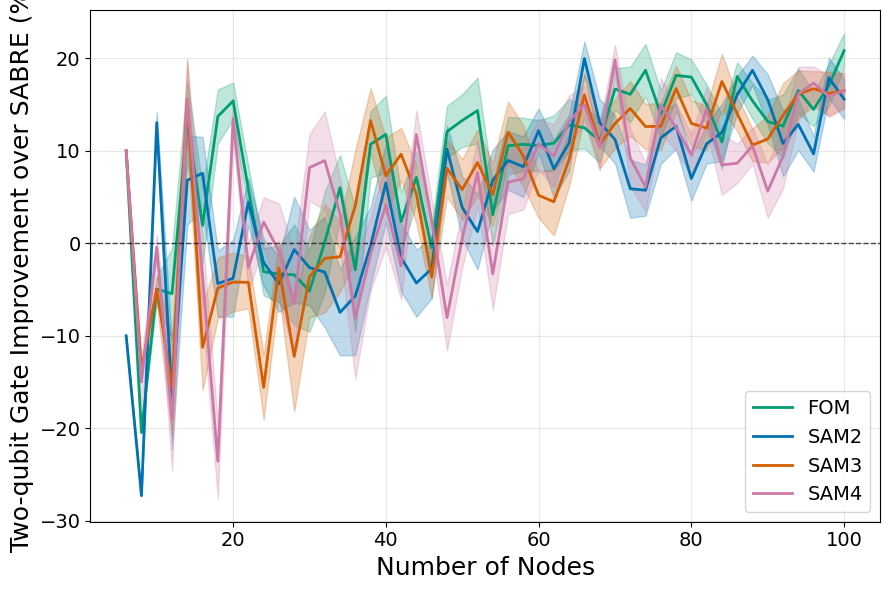

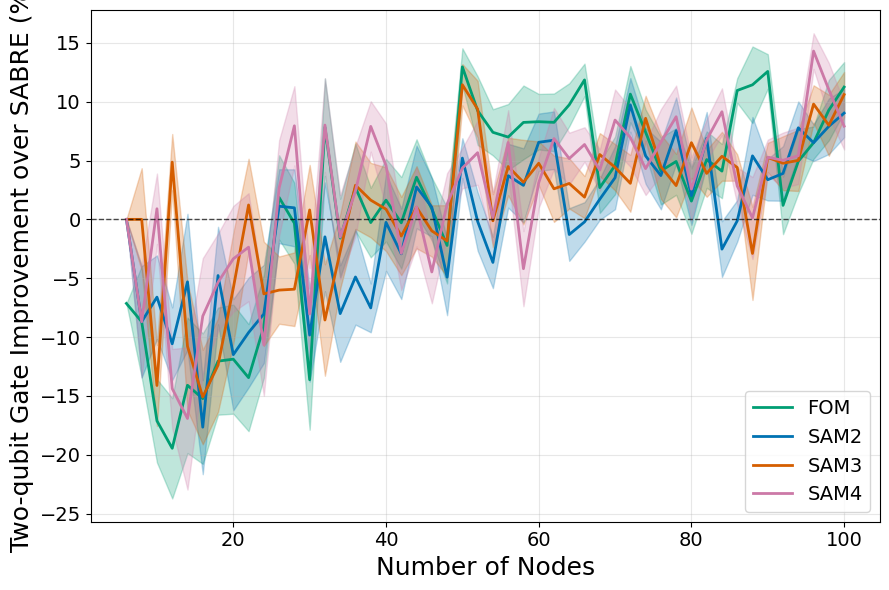

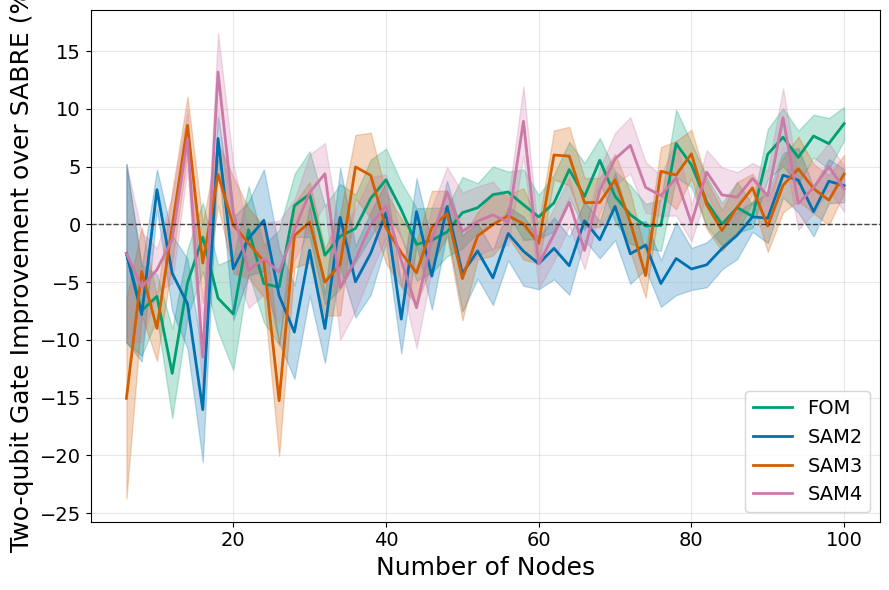

In [17]:
plot_percentage_improvements(twoq_imp_ba, node_list=nodes_ba, k_list=[2,3,4], params=params_ba, ylabel="Two-qubit Gate Improvement over SABRE (%)")

In [3]:
import networkx as nx
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from math import log, ceil
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXGate, RZZGate
from collections import defaultdict
import random
from tqdm import tqdm
from collections import deque
import networkx as nx
from collections import deque
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)
import matplotlib.pyplot as plt
import numpy as np
import random
import networkx as nx

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RZZGate
from collections import deque
from qiskit import transpile
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.transpiler import PassManager, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

from scipy.sparse.csgraph import laplacian
from scipy.linalg import eig, eigh
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist

def draw_graph_custom(G, node_labels=True, edge_labels=False, layout='kamada_kawai',
                      node_size=100, font_size=6, highlight_nodes=None, title=None):
    import math

    graph = nx.Graph()
    graph.add_nodes_from(G.nodes())
    graph.add_edges_from(G.edges())
    G=graph

    # Choose layout
    if layout == 'spring':
        pos = nx.spring_layout(G)
    elif layout == 'circular':
        pos = nx.circular_layout(G)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout == 'shell':
        pos = nx.shell_layout(G)
    elif layout == 'grid':
        # Create a grid layout with bottom-to-top rows
        n = G.number_of_nodes()
        side = math.ceil(math.sqrt(n))
        rows = math.ceil(n / side)
        pos = {
            node: (i % side, (i // side))  # bottom-to-top layout
            for i, node in enumerate(list(range(n)))
        }
    else:
        raise ValueError(f"Unsupported layout: {layout}")
    
    # Node colors
    if highlight_nodes is not None:
        node_colors = [
            'orange' if node in highlight_nodes else 'skyblue'
            for node in G.nodes()
        ]
    else:
        node_colors = 'skyblue'

    # Draw nodes and edges
    nx.draw(G, pos, with_labels=node_labels, node_size=node_size,
            font_size=font_size, edge_color='gray', node_color=node_colors)

    # Draw edge labels if requested
    if edge_labels:
        labels = nx.get_edge_attributes(G, 'weight')
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()

def graph_laplacian_embedding(G, k=2, alpha=0.95, normalized=False):
    '''Compute a spectral embedding of the graph (PageRank-like approach for directed graphs.)'''
    # Step 0: adjacency matrix
    if isinstance(G, nx.DiGraph):
        W = nx.to_numpy_array(G, nodelist=sorted(G.nodes()), weight=None)
        n = W.shape[0]
        e = np.ones((n, 1))

        # Out-degree diagonal matrix
        out_degrees = W.sum(axis=1)
        D0 = np.diag(out_degrees)

        # Step 1: Transition probability matrix P with perturbation
        mu = np.where(out_degrees == 0, 1, 0).reshape(-1, 1)  # dangling nodes
        D0_inv = np.linalg.pinv(D0)  # use pseudo-inverse to handle zeros
        P = alpha * (D0_inv @ W + (1/n) * mu @ e.T) + (1 - alpha) * (1/n) * e @ e.T

        # Step 2: Solve eigenproblem π^T P = π^T, i.e., find stationary distribution
        # Equivalent to solving P^T π = π
        eigvals, eigvecs = eig(P.T)
        idx = np.argmin(np.abs(eigvals - 1))  # eigenvalue closest to 1
        pi = np.real(eigvecs[:, idx])
        pi = pi / pi.sum()  # normalize so sum=1

        # Step 3: Construct Laplacian
        Phi = np.diag(pi)
        L = Phi - (Phi @ P + P.T @ Phi) / 2

        # Step 4: Generalized eigenvalue problem L v = λ Φ v
        eigvals, eigvecs = eig(np.linalg.pinv(Phi) @ L)
        eigvals = np.real(eigvals)
        eigvecs = np.real(eigvecs)

        # Sort eigenvectors by eigenvalues
        idx = np.argsort(eigvals)
        eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]

        # Skip the first trivial eigenvector (corresponding to eigenvalue ~0)
        Y = eigvecs[:, 1:k+1]
        # Y=[]
        # for i in range(n):
        #     Y.append([np.mean(eigvecs[i,1:k+1]), np.std(eigvecs[i,1:k+1])])
        # Y = np.array(Y)
        return Y
    elif isinstance(G, nx.Graph):
        if normalized:
            A = adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            degrees = np.sum(A, axis=1)
            D_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(degrees, 1e-12)))

            # --- Normalized Laplacian ---
            L_sym = np.eye(G.number_of_nodes()) - D_inv_sqrt @ A @ D_inv_sqrt

            # --- Compute eigenvalues and eigenvectors ---
            vals, vecs = eigh(L_sym)
            # Sort eigenpairs
            idx = np.argsort(vals)
            vals, vecs = vals[idx], vecs[:, idx]

            # Skip the first eigenvector (constant)
            X = vecs[:, 1:k+1]
        else:
            adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            L = laplacian(adj_matrix)
            vals, vecs = eigh(L)
            X = vecs[:, 1:k+1]  # skip the first (trivial) eigenvector
        return X
    else:
        return None
    

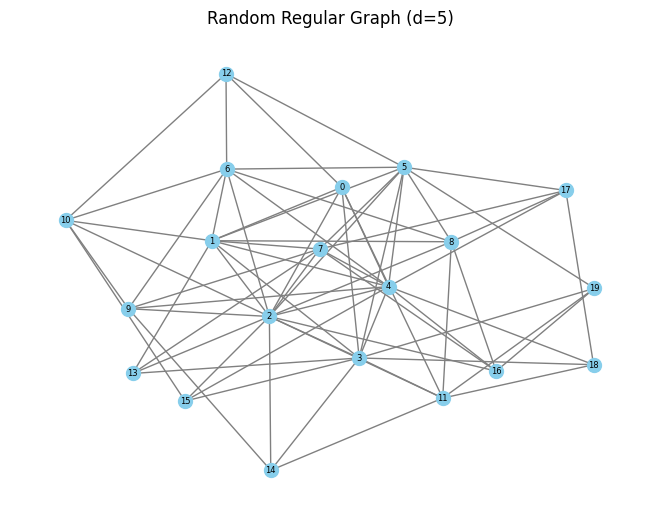

In [25]:
import matplotlib.pyplot as plt

from helper_functions import barabasi_albert_graph

n=20
# graph = nx.newman_watts_strogatz_graph(n=n, k=4, p=0.3, seed=0)
graph = barabasi_albert_graph(n=n, m=4, seed=0)
# graph = nx.random_regular_graph(n=n, d=6, seed=0)
draw_graph_custom(graph, node_labels=True, edge_labels=False, layout='kamada_kawai', node_size=100, font_size=6, highlight_nodes=None, title="Random Regular Graph (d=5)")

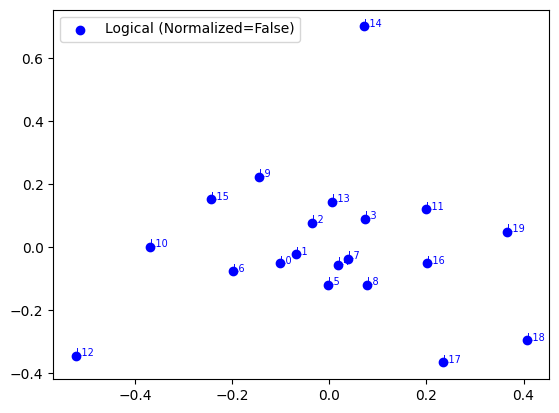

In [26]:
logical_embedding1 = graph_laplacian_embedding(graph, k=2, normalized=False)
logical_embedding2 = graph_laplacian_embedding(graph, k=2, normalized=True)
# logical_embedding = PCA(n_components=2).fit_transform(logical_embedding)
# logical_embedding = logical_embedding[:, 1:]

# Physical embedding
# plt.scatter(physical_embedding[:,0], physical_embedding[:,1], c='red', label='Physical')
# for i, (x, y) in enumerate(physical_embedding):
#     plt.text(x, y, f'P{i}', color='red')

# Logical embedding
plt.scatter(logical_embedding1[:,0], logical_embedding1[:,1], c='blue', label='Logical (Normalized=False)')
for i, (x, y) in enumerate(logical_embedding1):
    plt.text(x, y, f'L{i}', color='blue', size=7)
# plt.scatter(logical_embedding2[:,0], logical_embedding2[:,1], c='green', label='Logical (Normalized=True)')
# for i, (x, y) in enumerate(logical_embedding2):
#     plt.text(x, y, f'L{i}', color='green', size=7)

plt.legend()
plt.show()

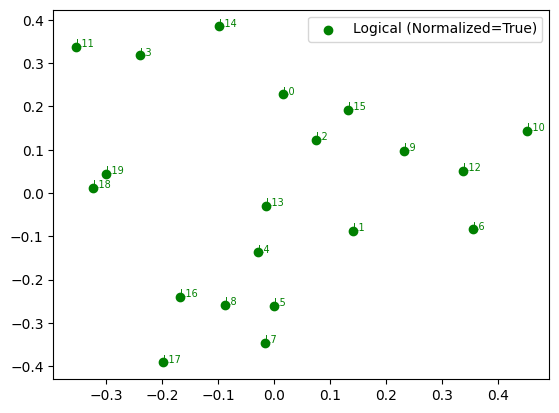

In [27]:
plt.scatter(logical_embedding2[:,0], logical_embedding2[:,1], c='green', label='Logical (Normalized=True)')
for i, (x, y) in enumerate(logical_embedding2):
    plt.text(x, y, f'L{i}', color='green', size=7)

plt.legend()
plt.show()